<a href="https://colab.research.google.com/github/shraddhabhongade29-prog/ML105/blob/main/PCA_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 6: Dimensionality Reduction using PCA and t-SNE

**Aim:** Apply PCA and t-SNE to reduce high-dimensional data to two dimensions, visualize the data, and compare classification accuracy before and after feature reduction.

**Author: Dr. Priya B. Pandharbale**

**Libraries:** NumPy, Pandas, Matplotlib, Scikit-learn

Run the cells one by one.

## 1. Import libraries and load the dataset

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

digits = load_digits()
X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))

Dataset shape: (1797, 64)
Number of classes: 10


## 2. Split the data and standardize features

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=44, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1437
Testing samples: 360


## 3. Accuracy using original features

In [5]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_original = knn.predict(X_test_scaled)

accuracy_original = accuracy_score(y_test, y_pred_original)
print("Accuracy with original 64 features:", round(accuracy_original, 4))

Accuracy with original 64 features: 0.9644


## 4. Apply PCA and compare accuracy

In [11]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

knn_pca = KNeighborsClassifier(n_neighbors=5)
knn_pca.fit(X_train_pca, y_train)
y_pred_pca = knn_pca.predict(X_test_pca)

accuracy_pca = accuracy_score(y_test, y_pred_pca)
print("Accuracy after PCA (2 features):", round(accuracy_pca, 3))
print("Total variance retained:", round(pca.explained_variance_ratio_.sum(), 3))

Accuracy after PCA (2 features): 0.519
Total variance retained: 0.216


## 5. Visualize PCA output

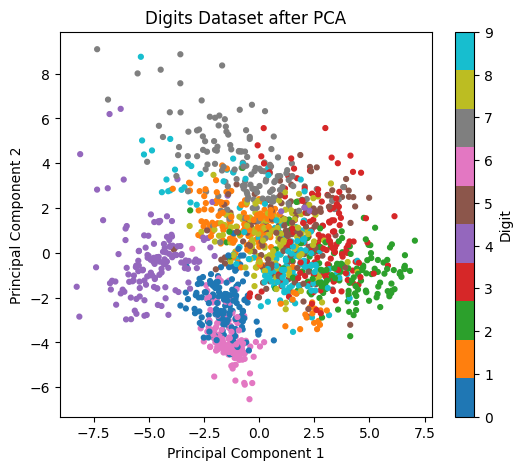

In [12]:
plt.figure(figsize=(6, 5))
scatter = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1],
                      c=y_train, cmap="tab10", s=12)
plt.title("Digits Dataset after PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Digit")
plt.show()

## 6. Apply t-SNE for 2D visualization

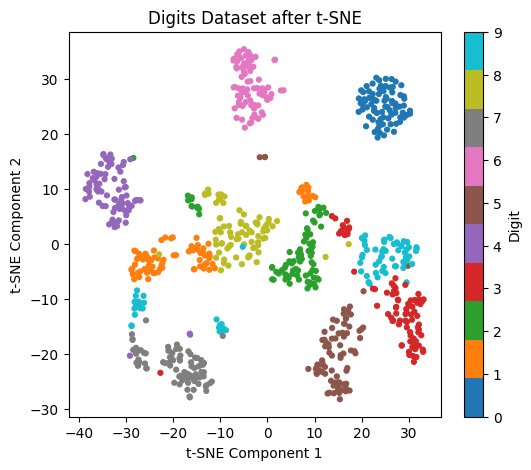

In [13]:
# t-SNE is used here for visualization. Fit it on a manageable sample.
sample_size = min(800, len(X))
X_sample = StandardScaler().fit_transform(X[:sample_size])
y_sample = y[:sample_size]

tsne = TSNE(n_components=2, random_state=42, perplexity=30,
            init="pca", learning_rate="auto")
X_tsne = tsne.fit_transform(X_sample)

plt.figure(figsize=(6, 5))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1],
                      c=y_sample, cmap="tab10", s=12)
plt.title("Digits Dataset after t-SNE")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.colorbar(scatter, label="Digit")
plt.show()

## 7. Compare results

In [16]:
print("Original features (64):", round(accuracy_original, 4))
print("PCA features (2):       ", round(accuracy_pca, 4))
print("\nPCA may reduce accuracy when only two components are retained.")
print("t-SNE is primarily a visualization technique; it is not used here")
print("as a standard train/test transformation for prediction.")

Original features (64): 0.9644
PCA features (2):        0.5194

PCA may reduce accuracy when only two components are retained.
t-SNE is primarily a visualization technique; it is not used here
as a standard train/test transformation for prediction.


## Observations
1. The original digit dataset contains 64 input features.
2. PCA transforms the original features into principal components.
3. Two PCA components allow the data to be visualized in 2D.
4. t-SNE helps reveal local groupings among digit classes.
5. Classification accuracy may decrease after reducing the features to only two dimensions.

## Result
PCA and t-SNE were applied to the Digits dataset. The data was visualized in two dimensions, and KNN accuracy using original features was compared with accuracy after PCA feature reduction.